In [1]:
# !pip install ucimlrepo scikit-learn pandas numpy matplotlib seaborn   # uncomment if needed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

# ---------- Load dataset directly from UCI ----------
wdbc = fetch_ucirepo(id=17)
X = wdbc.data.features.copy()
y = wdbc.data.targets.iloc[:, 0].astype(str).str.strip().str.upper().str[0].map({"B": 0, "M": 1})
CLASS_NAMES = ["Benign", "Malignant"]

print("Dataset Shape:", X.shape)
print("\nFirst 5 Records:")
print(X.head())
print("\nClass Distribution:")
print(y.map({0: "Benign", 1: "Malignant"}).value_counts())

# ---------- Train / test split ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

# ---------- Helper used by every model cell ----------
results = {}   # stores each model's scores for the optional comparison cell

def evaluate(name, model, cmap):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec  = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1   = f1_score(y_test, y_pred, average="weighted", zero_division=0)
    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1 Score": f1}

    print("\n" + "=" * 60)
    print(f"{name.upper()} RESULTS")
    print("=" * 60)
    print(f"Accuracy  : {acc * 100:.2f}%")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1 Score  : {f1:.4f}")
    print("\nClassification Report:\n")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:\n", cm)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted Class"); plt.ylabel("Actual Class")
    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout(); plt.show()

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    print("\n5-Fold Cross-Validation")
    print("Fold Scores:", np.round(scores, 4))
    print(f"Mean Accuracy: {scores.mean():.4f} | Std: {scores.std():.4f}")
    print(f"\n{name} Accuracy: {acc * 100:.2f}%")

Dataset Shape: (569, 30)

First 5 Records:
   radius1  texture1  perimeter1   area1  smoothness1  compactness1  \
0    17.99     10.38      122.80  1001.0      0.11840       0.27760   
1    20.57     17.77      132.90  1326.0      0.08474       0.07864   
2    19.69     21.25      130.00  1203.0      0.10960       0.15990   
3    11.42     20.38       77.58   386.1      0.14250       0.28390   
4    20.29     14.34      135.10  1297.0      0.10030       0.13280   

   concavity1  concave_points1  symmetry1  fractal_dimension1  ...  radius3  \
0      0.3001          0.14710     0.2419             0.07871  ...    25.38   
1      0.0869          0.07017     0.1812             0.05667  ...    24.99   
2      0.1974          0.12790     0.2069             0.05999  ...    23.57   
3      0.2414          0.10520     0.2597             0.09744  ...    14.91   
4      0.1980          0.10430     0.1809             0.05883  ...    22.54   

   texture3  perimeter3   area3  smoothness3  compactne


DECISION TREE RESULTS
Accuracy  : 92.11%
Precision : 0.9227
Recall    : 0.9211
F1 Score  : 0.9199

Classification Report:

              precision    recall  f1-score   support

      Benign       0.91      0.97      0.94        72
   Malignant       0.95      0.83      0.89        42

    accuracy                           0.92       114
   macro avg       0.93      0.90      0.91       114
weighted avg       0.92      0.92      0.92       114

Confusion Matrix:
 [[70  2]
 [ 7 35]]


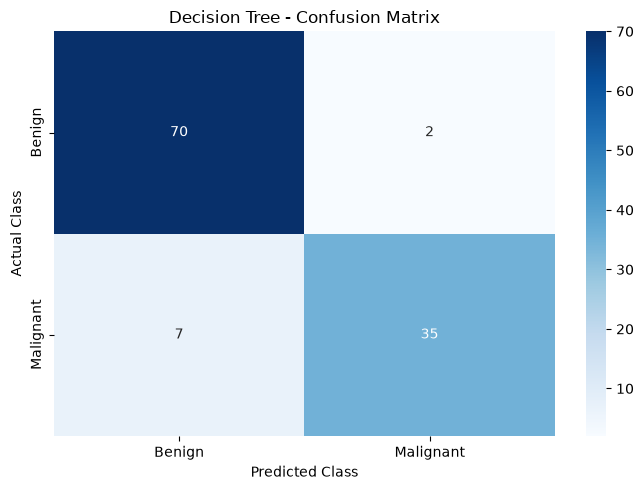


5-Fold Cross-Validation
Fold Scores: [0.9386 0.886  0.9298 0.9298 0.9558]
Mean Accuracy: 0.9280 | Std: 0.0230

Decision Tree Accuracy: 92.11%


In [2]:
decision_tree = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42)
evaluate("Decision Tree", decision_tree, "Blues")


RANDOM FOREST RESULTS
Accuracy  : 97.37%
Precision : 0.9747
Recall    : 0.9737
F1 Score  : 0.9735

Classification Report:

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Confusion Matrix:
 [[72  0]
 [ 3 39]]


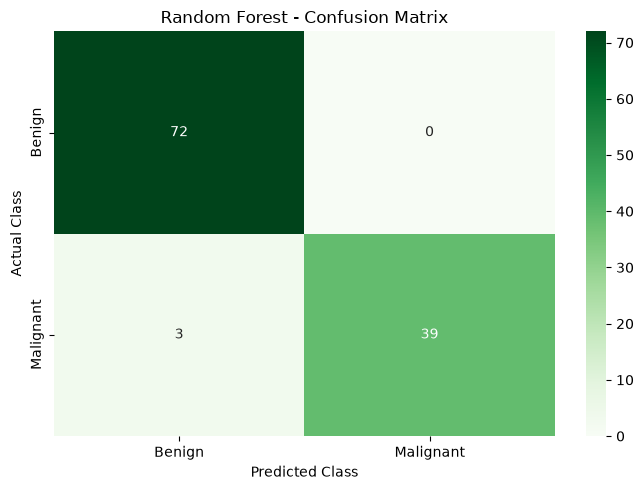


5-Fold Cross-Validation
Fold Scores: [0.9649 0.9386 0.9474 0.9474 0.9735]
Mean Accuracy: 0.9543 | Std: 0.0128

Random Forest Accuracy: 97.37%


In [3]:
random_forest = RandomForestClassifier(n_estimators=100, criterion="gini", random_state=42)
evaluate("Random Forest", random_forest, "Greens")


ADABOOST RESULTS
Accuracy  : 97.37%
Precision : 0.9747
Recall    : 0.9737
F1 Score  : 0.9735

Classification Report:

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Confusion Matrix:
 [[72  0]
 [ 3 39]]


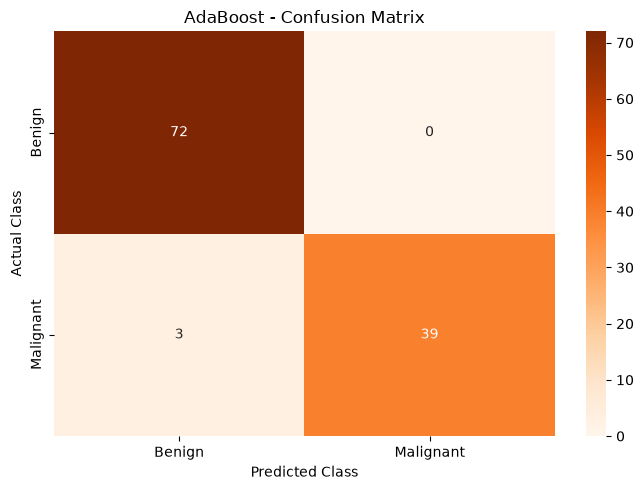


5-Fold Cross-Validation
Fold Scores: [0.9825 0.9298 0.9561 0.9737 0.9646]
Mean Accuracy: 0.9613 | Std: 0.0181

AdaBoost Accuracy: 97.37%


In [4]:
adaboost = AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)
evaluate("AdaBoost", adaboost, "Oranges")

## Cell 5 — Comparison (optional: run after whichever models you ran)

        Model  Accuracy  Precision   Recall  F1 Score
Decision Tree  0.921053   0.922669 0.921053  0.919879
Random Forest  0.973684   0.974737 0.973684  0.973465
     AdaBoost  0.973684   0.974737 0.973684  0.973465


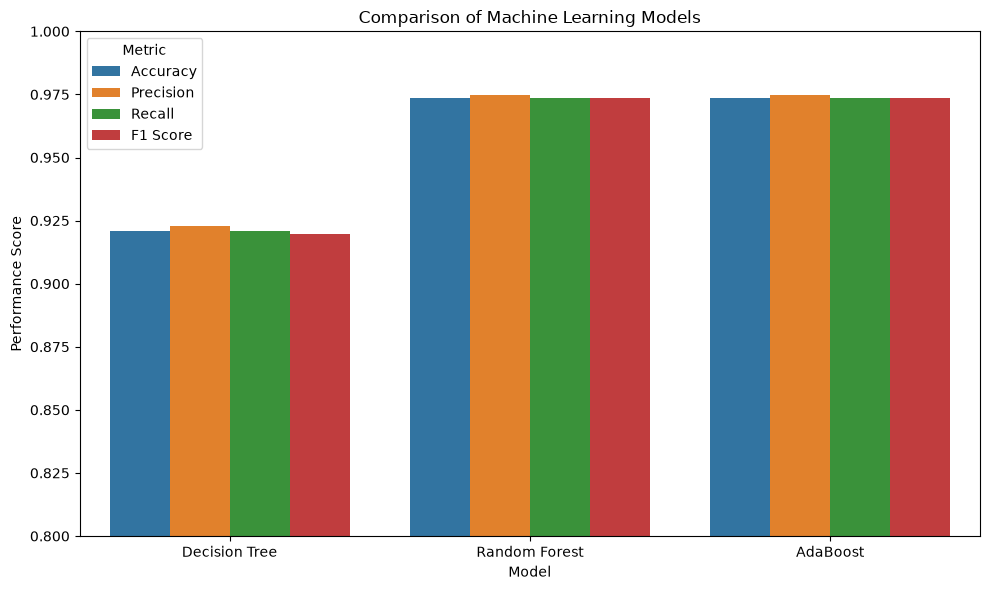


BEST MODEL: Random Forest  |  Accuracy = 97.37%


In [5]:
results_df = pd.DataFrame(results).T.reset_index().rename(columns={"index": "Model"})
print(results_df.to_string(index=False))

melted = results_df.melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(10, 6))
sns.barplot(data=melted, x="Model", y="Score", hue="Metric")
plt.title("Comparison of Machine Learning Models")
plt.ylim(0.8, 1.0); plt.ylabel("Performance Score")
plt.tight_layout(); plt.show()

best = results_df.loc[results_df["Accuracy"].idxmax()]
print(f"\nBEST MODEL: {best['Model']}  |  Accuracy = {best['Accuracy'] * 100:.2f}%")